

   
# Hands-on Project: Generative AI for Data Insights

The CSV file for this clean version of the dataset (Laptop Price Prediction using specifications) is available at the following URL:


URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"



# Reading the Dataset and Generating the Statistical Description
## Generating a Statistical Description of the Data Set

To read the CSV file into a DataFrame and generate a statistical description of the data set, provide the generative AI model with the following prompt.

### Prompt google/gemini-3.5-flash:

Write Python code to perform the following actions:

1. Import a data set from a CSV file, using the first row of the CSV file as the column headers.
2. Generate a statistical description of all features in the data set, including columns with the `object` data type.

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"

In [ ]:
import pandas as pd

# Define the dataset URL
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"

# 1. Import the dataset from the CSV file
# pd.read_csv automatically treats the first row as column headers by default
df = pd.read_csv(URL)

# 2. Generate a statistical description of all features, including object (categorical) columns
summary_stats = df.describe(include='all')

# Display the statistical description
print(summary_stats)

        Unnamed: 0.1  Unnamed: 0 Manufacturer    Category         GPU  \
count     238.000000  238.000000          238  238.000000  238.000000   
unique           NaN         NaN           11         NaN         NaN   
top              NaN         NaN         Dell         NaN         NaN   
freq             NaN         NaN           71         NaN         NaN   
mean      118.500000  118.500000          NaN    3.205882    2.151261   
std        68.848868   68.848868          NaN    0.776533    0.638282   
min         0.000000    0.000000          NaN    1.000000    1.000000   
25%        59.250000   59.250000          NaN    3.000000    2.000000   
50%       118.500000  118.500000          NaN    3.000000    2.000000   
75%       177.750000  177.750000          NaN    4.000000    3.000000   
max       237.000000  237.000000          NaN    5.000000    3.000000   

                OS    CPU_core  Screen_Size_inch  CPU_frequency      RAM_GB  \
count   238.000000  238.000000        238.00

Check if there are any missing values in the dataset.

Prompt: Is the csv clean version?

In [ ]:
# Check if there are any missing values in the dataset
df.isnull().sum()


# Creating Parameter Visualizations

Next, you need to visualize the distribution of various attributes against the target attribute, **`Price`**.

Different types of visualizations are suitable for different types of attributes:

- **Regression plots** are used for attributes with continuous values.
- **Box plots** are used for attributes with categorical values.

You can provide the generative AI model with a list of continuous and categorical attributes in a single prompt and ask it to generate Python code to create these plots.

### Continuous Attributes

The following attributes have continuous values:

- `CPU_frequency`
- `Screen_Size_inch`
- `Weight_pounds`

### Categorical Attributes

The following attributes have categorical values:

- `Category`
- `GPU`
- `OS`
- `CPU_core`
- `RAM_GB`
- `Storage_GB_SSD`

### Prompt

Write Python code to perform the following actions:

1. Create regression plots for the attributes `CPU_frequency`, `Screen_Size_inch`, and `Weight_pounds` against the target attribute `Price`.
2. Create box plots for the attributes `Category`, `GPU`, `OS`, `CPU_core`, `RAM_GB`, and `Storage_GB_SSD` against the target attribute `Price`.


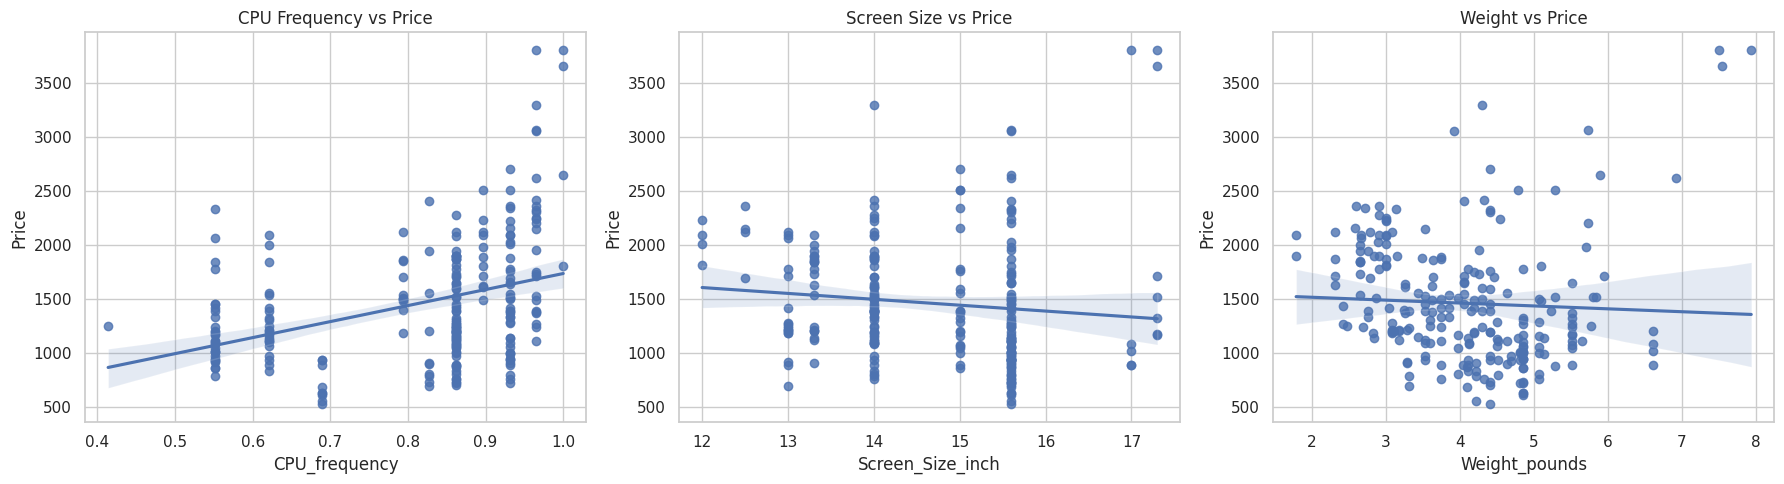

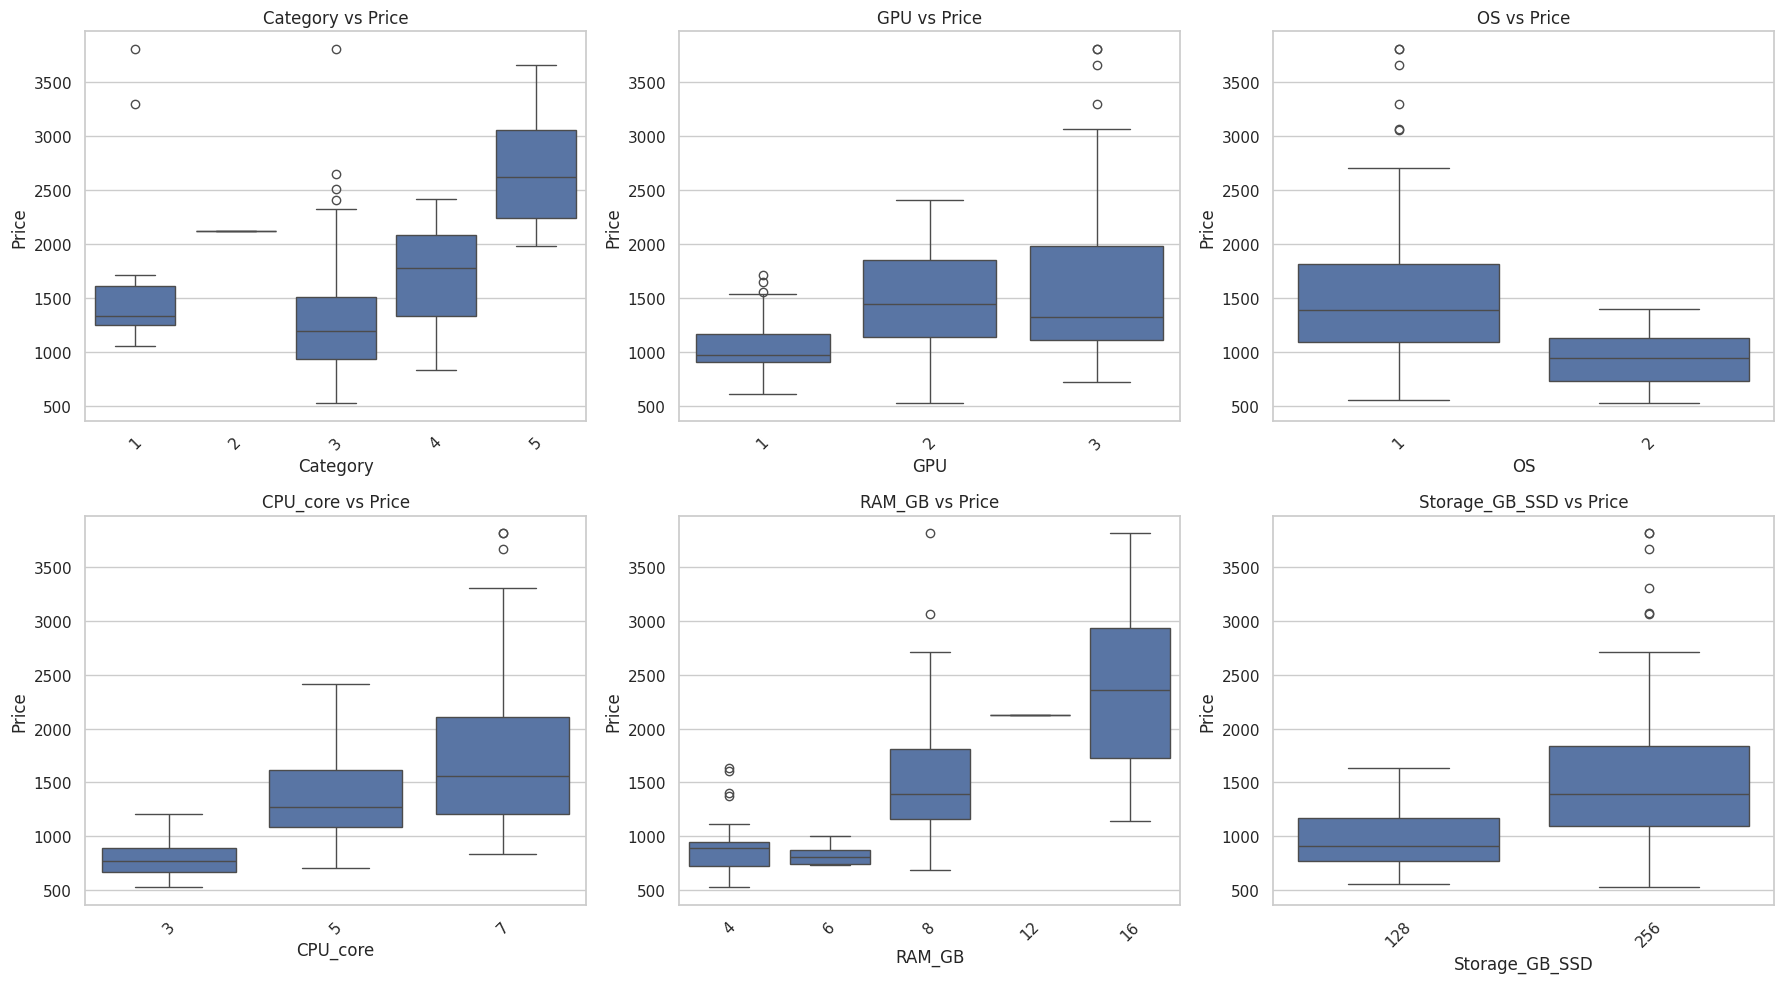

In [ ]:
import matplotlib.pyplot as plt
#import pandas as pd
import seaborn as sns

# Assuming df is already loaded from your dataset:
# URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"
# df = pd.read_csv(URL)

# 1. Create regression plots for CPU_frequency, Screen_Size_inch, and Weight_pounds against Price
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.regplot(x="CPU_frequency", y="Price", data=df)
plt.title("CPU Frequency vs Price")

plt.subplot(1, 3, 2)
sns.regplot(x="Screen_Size_inch", y="Price", data=df)
plt.title("Screen Size vs Price")

plt.subplot(1, 3, 3)
sns.regplot(x="Weight_pounds", y="Price", data=df)
plt.title("Weight vs Price")

plt.tight_layout()
plt.show()


# 2. Create box plots for Category, GPU, OS, CPU_core, RAM_GB, and Storage_GB_SSD against Price
box_features = ["Category", "GPU", "OS", "CPU_core", "RAM_GB", "Storage_GB_SSD"]

plt.figure(figsize=(18, 10))
for i, feature in enumerate(box_features, 1):
  plt.subplot(2, 3, i)
  sns.boxplot(x=feature, y="Price", data=df)
  plt.title(f"{feature} vs Price")
  plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Evaluate Dependence

Usually, not all parameters in a dataset have a direct or strong influence on the target variable. Understanding the level of influence is especially important for data scientists because predictive models use variables that have the greatest impact on the target variable.

To evaluate the interdependence of parameters, we can calculate the **correlation value, Pearson correlation coefficient, and p-value** of different attributes with respect to the target attribute.

## Prompt

Use the following prompt to generate Python code for evaluating dependence:

> Write Python code to perform the following tasks:
>
> 1. Evaluate the correlation value, Pearson correlation coefficient, and p-values for all numerical attributes against the target attribute `Price`.
> 2. Exclude the target variable's results against itself.
> 3. Display all evaluated values in a single Pandas DataFrame, with each individual attribute represented in a separate row.

In [ ]:
#import pandas as pd
from scipy import stats

# Assuming df is already loaded from your dataset:
# URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"
# df = pd.read_csv(URL)

# Select only numerical columns in the DataFrame
numeric_df = df.select_dtypes(include=["number"])

# Exclude 'Price' from the features so it doesn't correlate against itself
features = [col for col in numeric_df.columns if col != "Price"]

# List to store evaluation results
results = []

for col in features:
  # Drop rows with missing values in either the feature or Price for accurate calculation
  clean_data = df[[col, "Price"]].dropna()

  # Calculate Pearson correlation coefficient and p-value
  pearson_coef, p_value = stats.pearsonr(clean_data[col], clean_data["Price"])

  results.append(
      {
          "Attribute": col,
          "Pearson Correlation Coefficient": pearson_coef,
          "P-value": p_value,
      }
  )

# Create a single DataFrame with each attribute on a separate row
correlation_df = pd.DataFrame(results)

# Display the resulting DataFrame
print(correlation_df)

           Attribute  Pearson Correlation Coefficient       P-value
0       Unnamed: 0.1                         0.321933  3.851058e-07
1         Unnamed: 0                         0.321933  3.851058e-07
2           Category                         0.286243  7.225696e-06
3                GPU                         0.288298  6.166950e-06
4                 OS                        -0.221730  5.696643e-04
5           CPU_core                         0.459398  7.912950e-14
6   Screen_Size_inch                        -0.110644  8.853398e-02
7      CPU_frequency                         0.366666  5.502463e-09
8             RAM_GB                         0.549297  3.681561e-20
9     Storage_GB_SSD                         0.243421  1.489892e-04
10     Weight_pounds                        -0.050312  4.397694e-01
11    Screen-Full_HD                        -0.021075  7.463568e-01
12  Screen-IPS_panel                         0.021075  7.463568e-01


# Grouping and Pivots

You can perform another form of exploratory data analysis (EDA) by grouping different variables to create a **pivot table**. A pivot table presents a matrix of different combinations of values from the grouped variables. Each cell contains the average value of the target attribute for observations that share the same combination of values.

You can visualize this matrix using a **pseudocolor (`pcolor`) plot**.

For example, suppose you want to group the parameters **`GPU`**, **`CPU_core`**, and **`Price`**. In this case, you need to create a pivot table using `GPU` and `CPU_core` as the grouping variables, `Price` as the target variable, and the mean as the aggregation function. You can then generate a pseudocolor plot to visualize the resulting pivot table.

## Example Prompt

Write Python code to perform the following actions:

1. Group the attributes `GPU`, `CPU_core`, and `Price` available in a DataFrame named `df`.
2. Create a pivot table using `Price` as the target variable and the mean as the aggregation function.
3. Generate a pseudocolor (`pcolor`) plot to visualize the pivot table.

CPU_core           3            5            7
GPU                                           
1         769.250000   998.500000  1167.941176
2         785.076923  1462.197674  1744.621622
3         784.000000  1220.680000  1945.097561


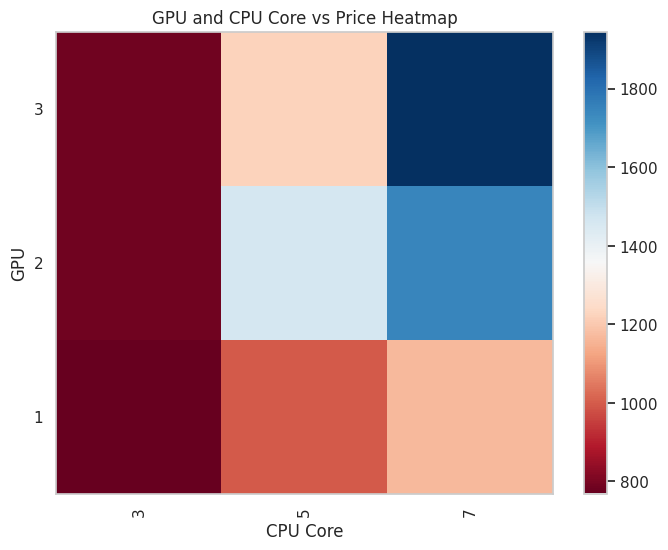

In [ ]:
#import matplotlib.pyplot as plt
import numpy as np
#import pandas as pd

# Assuming df is already loaded from your dataset:
# URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"
# df = pd.read_csv(URL)

# 1. Group the attributes GPU, CPU_core, and Price
df_gptest = df[["GPU", "CPU_core", "Price"]]
grouped_test = df_gptest.groupby(["GPU", "CPU_core"], as_index=False).mean()

# 2. Create a pivot table using Price as the target variable and mean as aggregation function
grouped_pivot = grouped_test.pivot(
    index="GPU", columns="CPU_core", values="Price"
)

# Fill missing values (NaN) with 0 for cleaner visualization
grouped_pivot = grouped_pivot.fillna(0)
print(grouped_pivot)

# 3. Generate a pseudocolor (pcolor) plot to visualize the pivot table
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.pcolor(grouped_pivot, cmap="RdBu")

# Set label names and ticks
row_labels = grouped_pivot.columns.tolist()
col_labels = grouped_pivot.index.tolist()

ax.set_xticks(np.arange(grouped_pivot.shape[1]) + 0.5, minor=False)
ax.set_yticks(np.arange(grouped_pivot.shape[0]) + 0.5, minor=False)

ax.set_xticklabels(row_labels, minor=False)
ax.set_yticklabels(col_labels, minor=False)

# Rotate x-axis labels if needed for better readability
plt.xticks(rotation=90)

# Add colorbar
fig.colorbar(im)
plt.title("GPU and CPU Core vs Price Heatmap")
plt.xlabel("CPU Core")
plt.ylabel("GPU")
plt.show()